# DYNI Odontocete Click Classification – Analyse des données
Notebook de la partie **1.2 (écoute), 1.4 (rappels fréquentiels) et 2 (Analyse des données)**.

Plan : statistiques globales → structure temporelle et position du clic → variation intra-classe → similarités inter-classes.
Le notebook se termine par quelques pistes qui annoncent la partie 5 (biais d'enregistrement).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import hilbert
from scipy.ndimage import uniform_filter1d
from scipy.stats import kurtosis
from sklearn.decomposition import PCA
from IPython.display import Audio, display

sns.set_theme(style="whitegrid", context="notebook")

X_train = np.load('./DOCC10_train/DOCC10_Xtrain.npy')
X_test  = np.load('./DOCC10_test/DOCC10_Xtest.npy', mmap_mode='r')   # mmap : on ne charge que ce dont on a besoin
ids_train = pd.read_csv('./DOCC10_train/DOCC10_Xtrain_IDS.csv')
Y_train_df = pd.read_csv('./DOCC10_Ytrain.csv', index_col=0)

ids_train.columns = ['ID', 'ROW']
ids_train = ids_train.astype(int)
df = ids_train.merge(Y_train_df, left_on='ID', right_index=True, how='left')
df = df.sort_values('ROW').reset_index(drop=True)

y_labels = df['TARGET'].values
especes = sorted(df['TARGET'].unique())
esp2idx = {e: i for i, e in enumerate(especes)}

fe = 200_000
L = X_train.shape[1]
t_ms = np.arange(L) / fe * 1000

noms = {0:'Gg',1:'Gma',2:'La',3:'Mb',4:'Me',5:'Pm',6:'Ssp',7:'UDA',8:'UDB',9:'Zc'}
lab = {e: noms.get(e, str(e)) for e in especes}      # étiquette courte
palette = dict(zip(especes, sns.color_palette("tab10", len(especes))))

print(f"X_train : {X_train.shape}, dtype={X_train.dtype}")
print(f"X_test  : {X_test.shape}, dtype={X_test.dtype}")
print(f"y_labels: {y_labels.shape}")

X_train : (113120, 8192), dtype=float32
X_test  : (20960, 8192), dtype=float32
y_labels: (113120,)


In [2]:
# Sous-échantillon stratifié pour les calculs lourds (enveloppe, FFT...)
rng = np.random.default_rng(0)
N_PER_CLASS = 500
idx_sub = np.concatenate([rng.choice(np.where(y_labels == e)[0], N_PER_CLASS, replace=False) for e in especes])
X_sub = X_train[idx_sub].astype(np.float32)
y_sub = y_labels[idx_sub]

idx_test = np.sort(rng.choice(len(X_test), 2000, replace=False))
Xt_sub = np.asarray(X_test[idx_test]).astype(np.float32)
print(X_sub.shape, Xt_sub.shape)

(5000, 8192) (2000, 8192)


## 1.2 Écoute des signaux
Les clics durent quelques dizaines de microsecondes : on les ralentit (×20) pour les rendre audibles et les comparer à l'oreille.

In [3]:
SLOW = 20
for e in especes:
    i = np.where(y_sub == e)[0][0]
    x = X_sub[i] / (np.abs(X_sub[i]).max() + 1e-12)
    print(f"Classe {e} – {lab[e]}")
    display(Audio(x, rate=fe // SLOW))

Classe GG – GG


Classe GMA – GMA


Classe LA – LA


Classe MB – MB


Classe ME – ME


Classe PM – PM


Classe SSP – SSP


Classe UDA – UDA


Classe UDB – UDB


Classe ZC – ZC


## 1.4 Rappels sur le domaine fréquentiel
- Fréquence d'échantillonnage $f_e = 200$ kHz, donc bande utile $[0, f_e/2] = [0, 100]$ kHz (Nyquist).
- Pour un signal de $N$ points, la TFD donne $X[k]=\sum_n x[n]\,w[n]\,e^{-2i\pi kn/N}$, à la fréquence $f_k = k f_e/N$. La résolution est $f_e/N$ : 24 Hz pour $N=8192$, 195 Hz pour une fenêtre de 1024 points.
- Une fenêtre de Hann limite les fuites spectrales. On travaille en **log-spectre** $20\log_{10}|X[k]|$ (dB), qui reflète mieux la dynamique que le spectre linéaire.
- Le **signal analytique** $x_a = x + i\,\mathcal{H}[x]$ donne l'**enveloppe** $|x_a|$, utilisée pour localiser le clic.
- Les clics d'odontocètes sont des impulsions courtes à large bande ; la **fréquence pic** et le **centroïde spectral** les caractérisent.

## 1.3 Formalisation du problème (rappel)
Chaque exemple est un signal $x\in\mathbb{R}^{8192}$ ; on cherche $f:\mathbb{R}^{8192}\to\{0,\dots,9\}$ qui maximise l'accuracy. Les classes sont équilibrées (≈ 11 312 exemples/classe en train, 2 096 en test).

## 2.1 Statistiques globales du jeu de données

NaN / inf dans X_train : 0 / 0
GG (GG)      11312
GMA (GMA)    11312
LA (LA)      11312
MB (MB)      11312
ME (ME)      11312
PM (PM)      11312
SSP (SSP)    11312
UDA (UDA)    11312
UDB (UDB)    11312
ZC (ZC)      11312


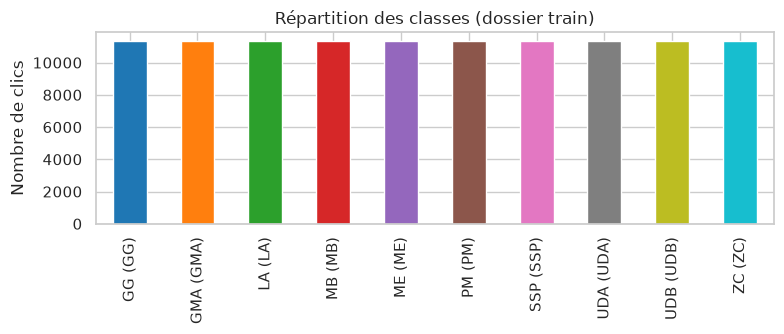

In [16]:
print("NaN / inf dans X_train :", int(np.isnan(X_train).sum()), "/", int(np.isinf(X_train).sum()))
counts = pd.Series(y_labels).value_counts().sort_index()
counts.index = [f"{e} ({lab[e]})" for e in counts.index]
print(counts.to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
counts.plot.bar(ax=ax, color=[palette[e] for e in especes])
ax.set_ylabel("Nombre de clics"); ax.set_title("Répartition des classes (dossier train)")
plt.tight_layout(); plt.show()

pic             rms         moyenne           kurtosis            
          mean     std    mean     std    mean     std       mean         std
classe                                                                       
GG      0.0095  0.0097  0.0020  0.0041  0.0003  0.0034  11.005100   46.275002
GMA     0.0244  0.0353  0.0025  0.0050 -0.0004  0.0051  86.358902  265.734406
LA      0.0120  0.0140  0.0013  0.0007  0.0000  0.0008  29.406200  137.938004
MB      0.0141  0.0359  0.0018  0.0016  0.0000  0.0010  20.239599   74.090500
ME      0.0120  0.0186  0.0018  0.0013  0.0000  0.0009  24.257900   82.554100
PM      0.0123  0.0153  0.0067  0.0077  0.0003  0.0068   2.263700   13.347100
SSP     0.0086  0.0037  0.0030  0.0017  0.0000  0.0006  -0.443400    0.491300
UDA     0.0110  0.0131  0.0014  0.0009 -0.0000  0.0010  20.800800  104.148102
UDB     0.0215  0.0338  0.0057  0.0170 -0.0004  0.0160  57.837399  219.584000
ZC      0.0162  0.0315  0.0020  0.0019  0.0000  0.0004  18.550200   58.207401

/tmp/ipykernel_26621/298937126.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=stats, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], palette=[palette[e] for e in especes])
/tmp/ipykernel_26621/298937126.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=stats, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], palette=[palette[e] for e in especes])
/tmp/ipykernel_26621/298937126.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=stats, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], pale

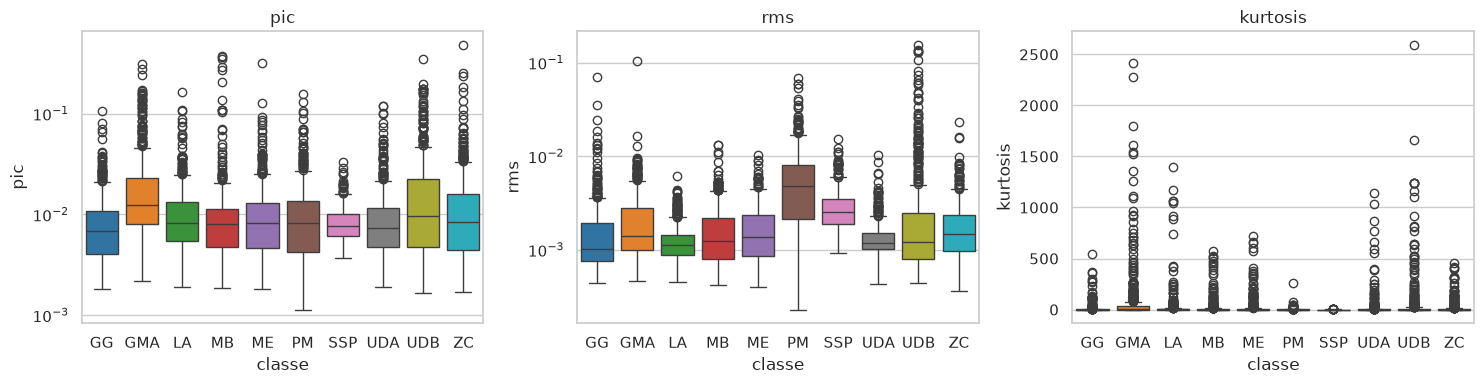

Amplitude max globale (sous-échantillon) : 0.4111328 | min : -0.4862976


In [5]:
# Statistiques d'amplitude par classe (sur le sous-échantillon)
peak = np.abs(X_sub).max(1)
rms  = np.sqrt((X_sub**2).mean(1))
dc   = X_sub.mean(1)
kurt = kurtosis(X_sub, axis=1)          # grand = signal impulsionnel

stats = pd.DataFrame({'classe': [lab[e] for e in y_sub], 'pic': peak, 'rms': rms, 'moyenne': dc, 'kurtosis': kurt})
display(stats.groupby('classe').agg(['mean', 'std']).round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, logy in zip(axes, ['pic', 'rms', 'kurtosis'], [True, True, False]):
    sns.boxplot(data=stats, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], palette=[palette[e] for e in especes])
    if logy: ax.set_yscale('log')
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("Amplitude max globale (sous-échantillon) :", X_sub.max(), "| min :", X_sub.min())

## 2.2 Structure temporelle et position du clic

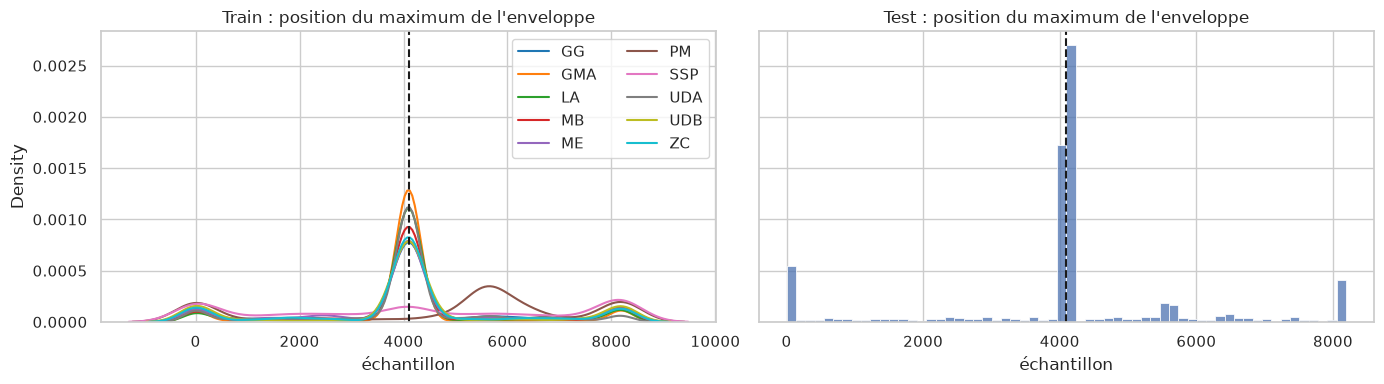

Train : 52.3% des clics à ±100 échantillons du centre
Test  : 60.3% des clics à ±100 échantillons du centre


In [6]:
def envelope(X, smooth=9):
    return uniform_filter1d(np.abs(hilbert(X, axis=1)), size=smooth, axis=1)

env_sub = envelope(X_sub)
env_te  = envelope(Xt_sub)
pos_sub = env_sub.argmax(1)
pos_te  = env_te.argmax(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for e in especes:
    sns.kdeplot(pos_sub[y_sub == e], ax=axes[0], color=palette[e], label=lab[e], bw_adjust=0.5)
axes[0].set_title("Train : position du maximum de l'enveloppe")
axes[0].set_xlabel("échantillon"); axes[0].axvline(L // 2, color='k', ls='--'); axes[0].legend(ncol=2)
sns.histplot(pos_te, bins=60, ax=axes[1], stat='density')
axes[1].set_title("Test : position du maximum de l'enveloppe"); axes[1].set_xlabel("échantillon")
axes[1].axvline(L // 2, color='k', ls='--')
plt.tight_layout(); plt.show()

print(f"Train : {np.mean(np.abs(pos_sub - L//2) < 100):.1%} des clics à ±100 échantillons du centre")
print(f"Test  : {np.mean(np.abs(pos_te  - L//2) < 100):.1%} des clics à ±100 échantillons du centre")

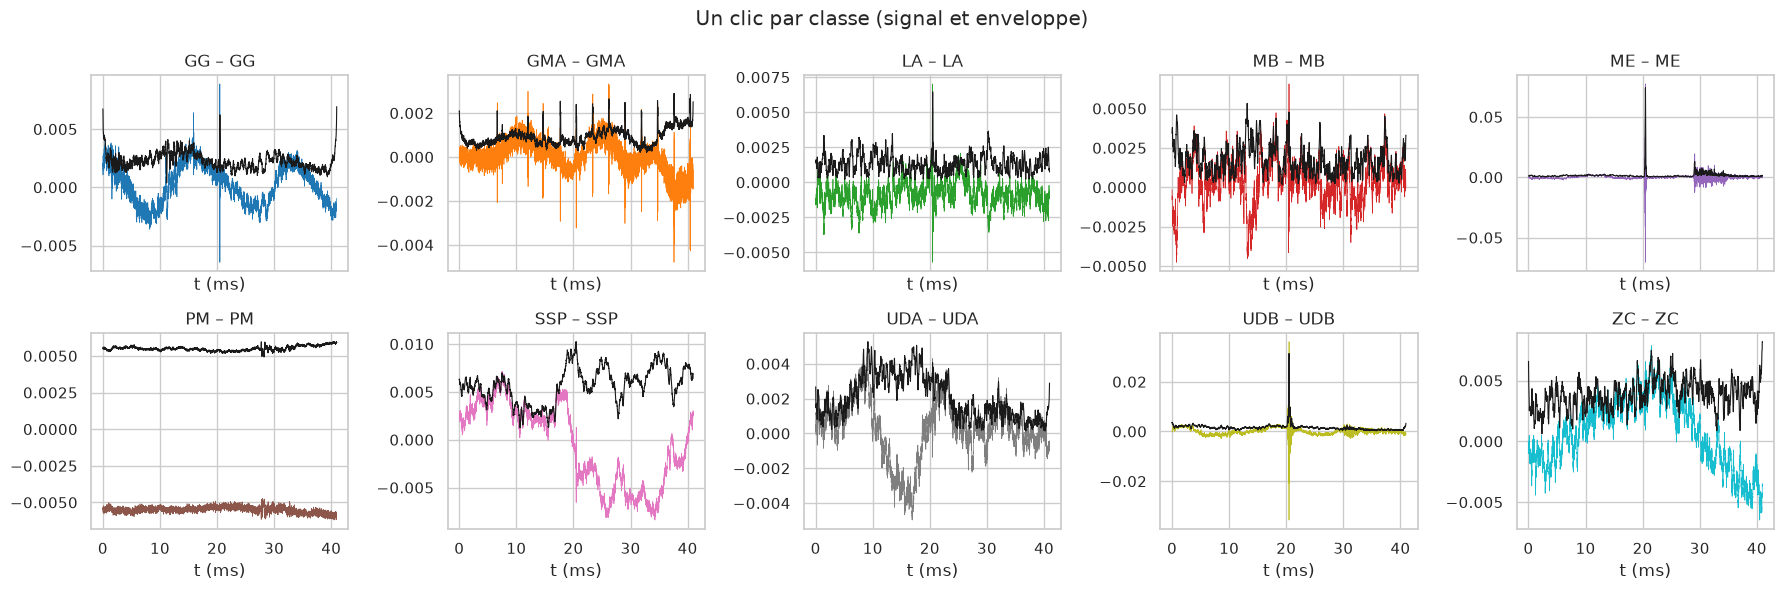

In [7]:
# Un exemple par classe, signal + enveloppe
fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharex=True)
for ax, e in zip(axes.ravel(), especes):
    i = np.where(y_sub == e)[0][0]
    ax.plot(t_ms, X_sub[i], lw=0.5, color=palette[e])
    ax.plot(t_ms, env_sub[i], 'k', lw=0.8)
    ax.set_title(f"{e} – {lab[e]}"); ax.set_xlabel("t (ms)")
plt.suptitle("Un clic par classe (signal et enveloppe)"); plt.tight_layout(); plt.show()

/tmp/ipykernel_26621/1632055035.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=feat, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], palette=[palette[e] for e in especes])
/tmp/ipykernel_26621/1632055035.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=feat, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], palette=[palette[e] for e in especes])
/tmp/ipykernel_26621/1632055035.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=feat, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], pale

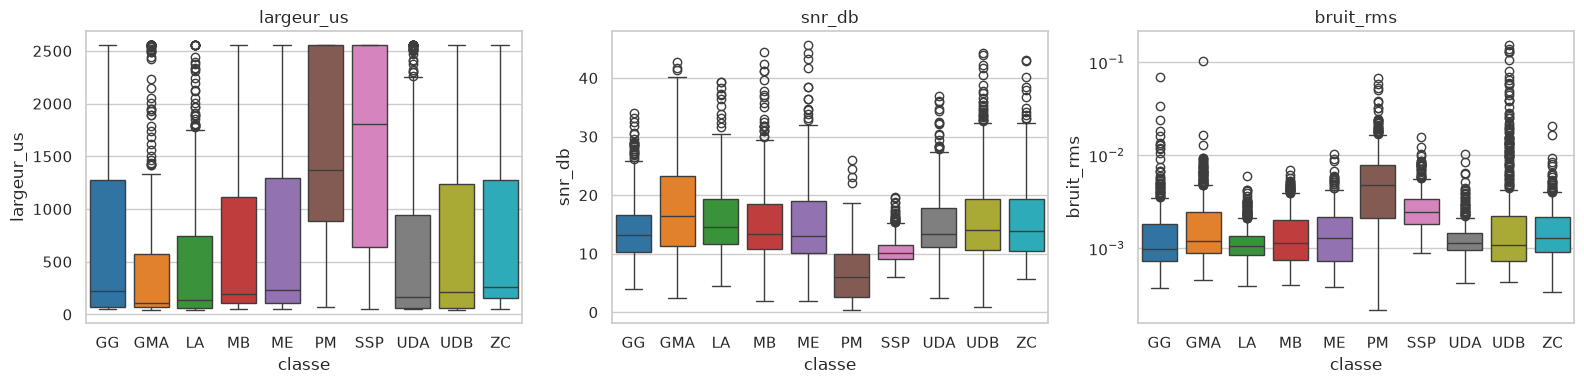

,largeur_us,bruit_rms,snr_db
classe,,,
GG,220.0,0.001,13.136
GMA,105.0,0.001,16.426
LA,132.5,0.001,14.556
MB,190.0,0.001,13.388
ME,235.0,0.001,13.021
PM,1372.5,0.005,6.055
SSP,1805.0,0.002,10.130
UDA,170.0,0.001,13.285
UDB,210.0,0.001,14.103


In [8]:
# Largeur du clic (durée où l'enveloppe > 50 % du pic, soit -6 dB) et SNR
HALF = 256
ar = np.arange(L)
peak_env = env_sub.max(1)
width = np.array([(env_sub[i, max(0, pos_sub[i]-HALF):pos_sub[i]+HALF] > 0.5 * peak_env[i]).sum() for i in range(len(X_sub))]) / fe * 1e6  # µs

far = np.abs(ar[None, :] - pos_sub[:, None]) > HALF           # échantillons loin du clic = bruit
noise_rms = np.sqrt(np.where(far, X_sub**2, 0).sum(1) / far.sum(1))
snr_db = 20 * np.log10(peak_env / (noise_rms + 1e-12))

feat = pd.DataFrame({'classe': [lab[e] for e in y_sub], 'largeur_us': width, 'bruit_rms': noise_rms, 'snr_db': snr_db})
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['largeur_us', 'snr_db', 'bruit_rms']):
    sns.boxplot(data=feat, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], palette=[palette[e] for e in especes])
    if col == 'bruit_rms': ax.set_yscale('log')
    ax.set_title(col)
plt.tight_layout(); plt.show()
display(feat.groupby('classe').median().round(3))

## 2.3 Variation intra-classe

/tmp/ipykernel_26621/1183946536.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=spec_feat, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], palette=[palette[e] for e in especes], cut=0)
/tmp/ipykernel_26621/1183946536.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=spec_feat, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], palette=[palette[e] for e in especes], cut=0)


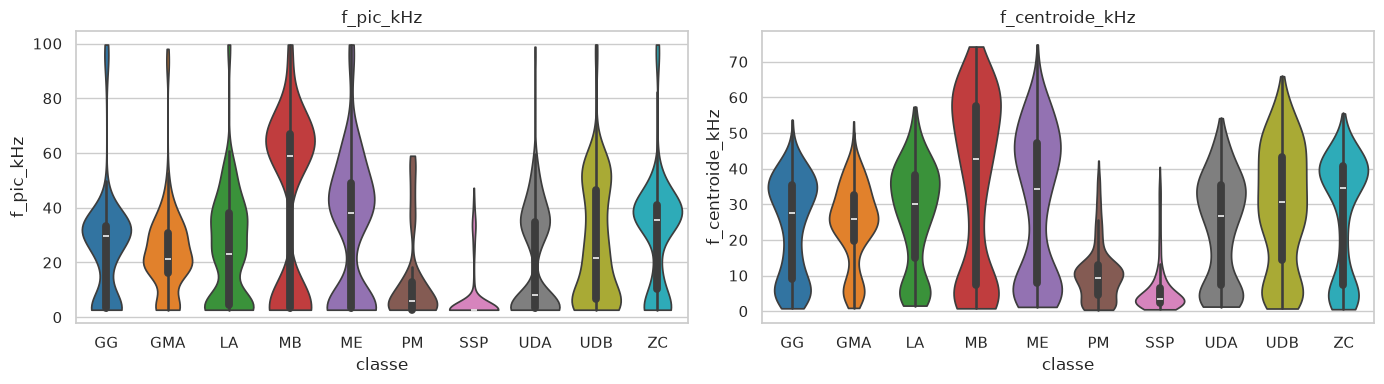

f_pic_kHz       f_centroide_kHz      
            mean   std            mean   std
classe                                      
GG          25.8  20.4            23.6  13.7
GMA         23.7  15.8            24.6  11.2
LA          24.8  19.8            27.2  14.4
MB          41.5  32.0            36.1  24.0
ME          32.7  25.6            29.8  20.2
PM          13.6  16.4            10.3   8.1
SSP          6.7  10.2             6.2   7.3
UDA         21.2  19.3            23.5  14.7
UDB         27.1  21.9            29.3  17.0
ZC          30.3  20.5            27.3  16.4

In [9]:
# Clics recentrés (fenêtre de 512 points autour du max de l'enveloppe) pour les analyses spectrales
def extract(X, pos, half=256):
    c = np.clip(pos, half, X.shape[1] - half)
    return np.take_along_axis(X, c[:, None] + np.arange(-half, half)[None, :], axis=1)

NB = 128                                  # bandes de fréquence
fbin = (np.arange(NB) + 0.5) * (fe / 2) / NB / 1000     # kHz

def log_spectrum(C):
    C = C - C.mean(1, keepdims=True)
    C = C / (np.abs(C).max(1, keepdims=True) + 1e-12)
    S = np.abs(np.fft.rfft(C * np.hanning(C.shape[1]), n=1024, axis=1))[:, :512]
    S = S.reshape(len(C), NB, -1).mean(2)
    return 20 * np.log10(S + 1e-6)

C_sub = extract(X_sub, pos_sub)
LS = log_spectrum(C_sub)                  # (5000, 128)

# Fréquence pic et centroïde
P = 10 ** (LS / 10)
f_peak = fbin[LS[:, 3:].argmax(1) + 3]
f_cent = (P * fbin).sum(1) / P.sum(1)
spec_feat = pd.DataFrame({'classe': [lab[e] for e in y_sub], 'f_pic_kHz': f_peak, 'f_centroide_kHz': f_cent})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['f_pic_kHz', 'f_centroide_kHz']):
    sns.violinplot(data=spec_feat, x='classe', y=col, ax=ax, order=[lab[e] for e in especes], palette=[palette[e] for e in especes], cut=0)
    ax.set_title(col)
plt.tight_layout(); plt.show()
display(spec_feat.groupby('classe').agg(['mean', 'std']).round(1))

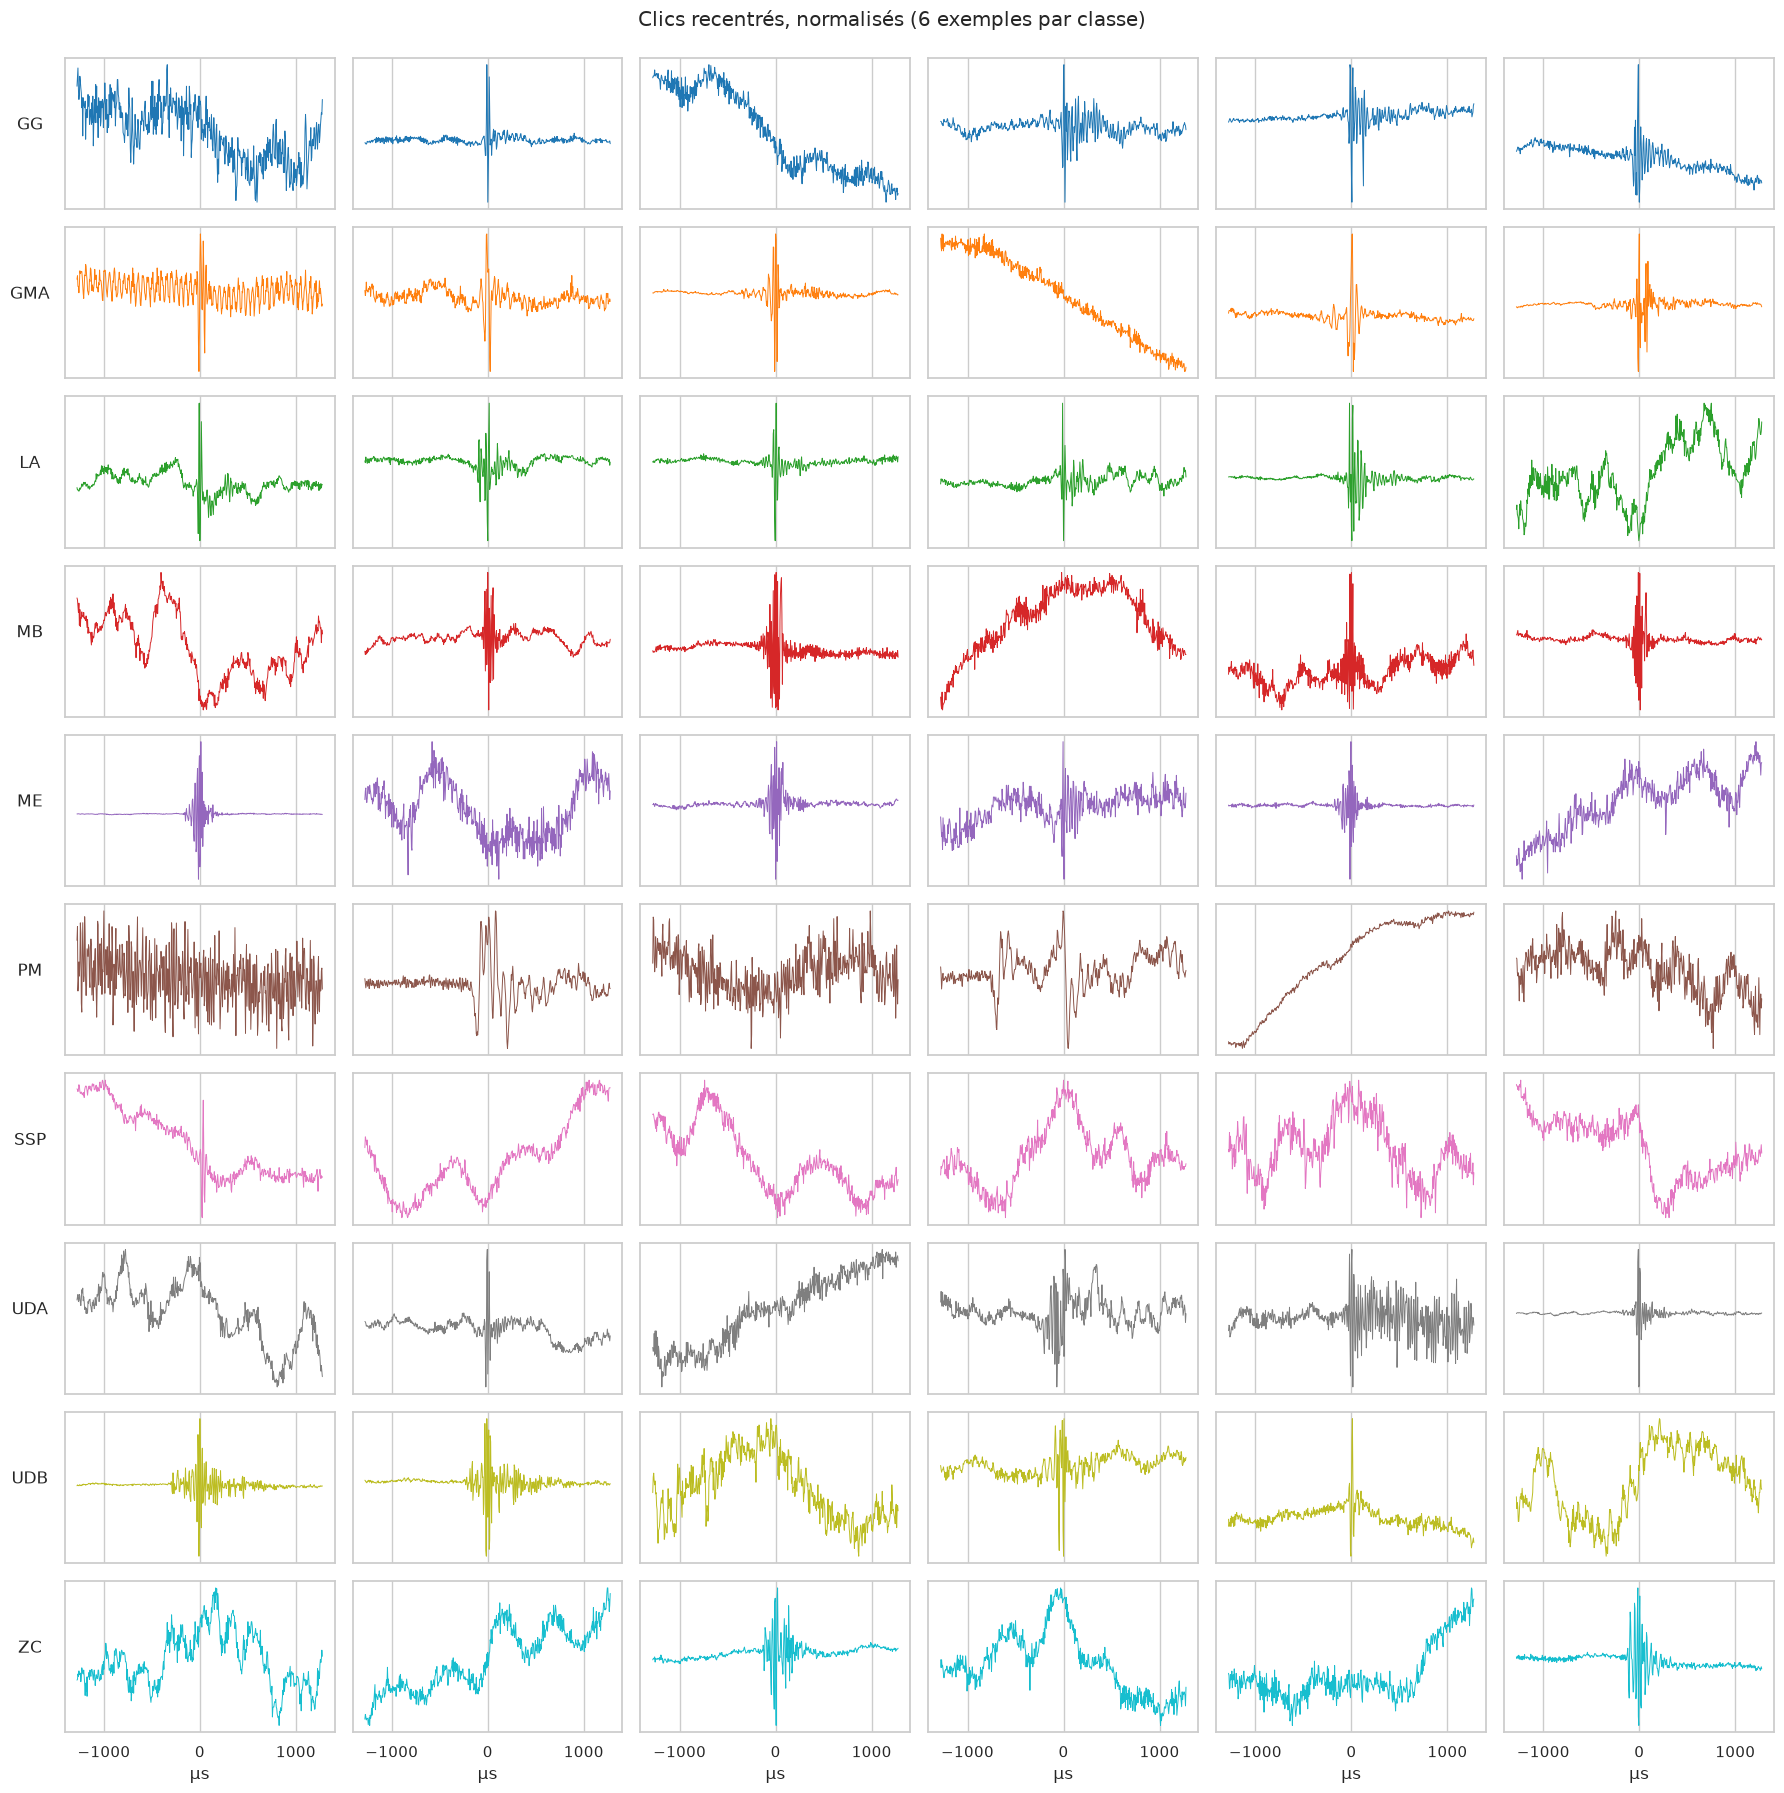

In [10]:
# Variabilité de la forme d'onde : 6 clics recentrés par classe
tc = (np.arange(512) - 256) / fe * 1e6
fig, axes = plt.subplots(10, 6, figsize=(18, 18), sharex=True)
for r, e in enumerate(especes):
    ids = np.where(y_sub == e)[0][:6]
    for c, i in enumerate(ids):
        axes[r, c].plot(tc, C_sub[i] / np.abs(C_sub[i]).max(), lw=0.7, color=palette[e])
        axes[r, c].set_yticks([])
    axes[r, 0].set_ylabel(lab[e], rotation=0, labelpad=25, fontsize=12)
for c in range(6): axes[-1, c].set_xlabel("µs")
plt.suptitle("Clics recentrés, normalisés (6 exemples par classe)", y=0.995); plt.tight_layout(); plt.show()

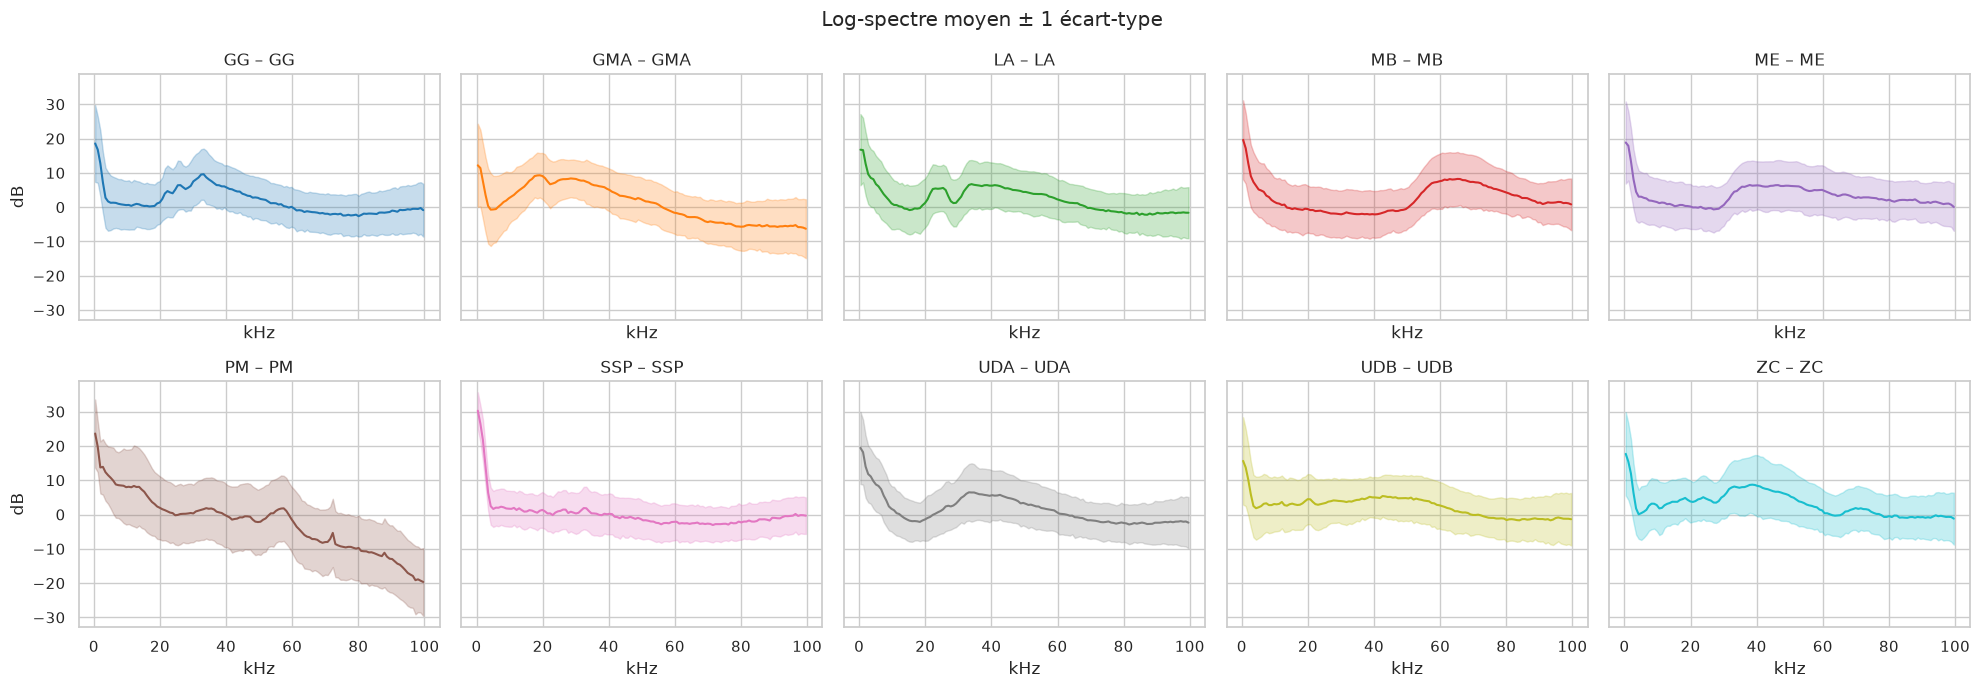

In [11]:
# Log-spectre moyen ± écart-type par classe
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True, sharey=True)
for ax, e in zip(axes.ravel(), especes):
    m = LS[y_sub == e]
    mu, sd = m.mean(0), m.std(0)
    ax.plot(fbin, mu, color=palette[e]); ax.fill_between(fbin, mu - sd, mu + sd, color=palette[e], alpha=0.25)
    ax.set_title(f"{e} – {lab[e]}"); ax.set_xlabel("kHz")
axes[0, 0].set_ylabel("dB"); axes[1, 0].set_ylabel("dB")
plt.suptitle("Log-spectre moyen ± 1 écart-type"); plt.tight_layout(); plt.show()

## 2.4 Similarités entre classes

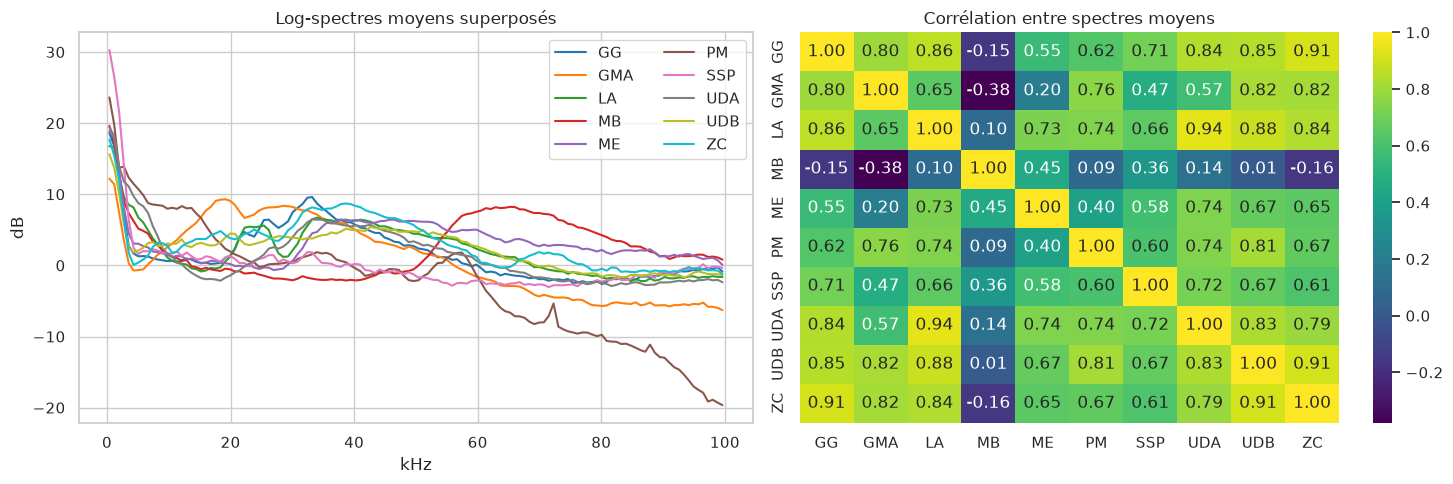

  A   B     corr
 LA UDA 0.944625
 GG  ZC 0.908795
UDB  ZC 0.907369
 LA UDB 0.883398
 GG  LA 0.860004
 GG UDB 0.849088
 GG UDA 0.842197
 LA  ZC 0.838125


In [12]:
mean_spec = np.stack([LS[y_sub == e].mean(0) for e in especes])      # (10, 128)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for e, m in zip(especes, mean_spec):
    axes[0].plot(fbin, m, color=palette[e], label=lab[e])
axes[0].set_xlabel("kHz"); axes[0].set_ylabel("dB"); axes[0].legend(ncol=2); axes[0].set_title("Log-spectres moyens superposés")

corr = np.corrcoef(mean_spec)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='viridis', xticklabels=[lab[e] for e in especes],
            yticklabels=[lab[e] for e in especes], ax=axes[1], vmin=corr.min(), vmax=1)
axes[1].set_title("Corrélation entre spectres moyens")
plt.tight_layout(); plt.show()

# Paires de classes les plus proches
pairs = [(lab[especes[i]], lab[especes[j]], corr[i, j]) for i in range(10) for j in range(i+1, 10)]
print(pd.DataFrame(pairs, columns=['A', 'B', 'corr']).sort_values('corr', ascending=False).head(8).to_string(index=False))

Variance expliquée : [0.303 0.177]


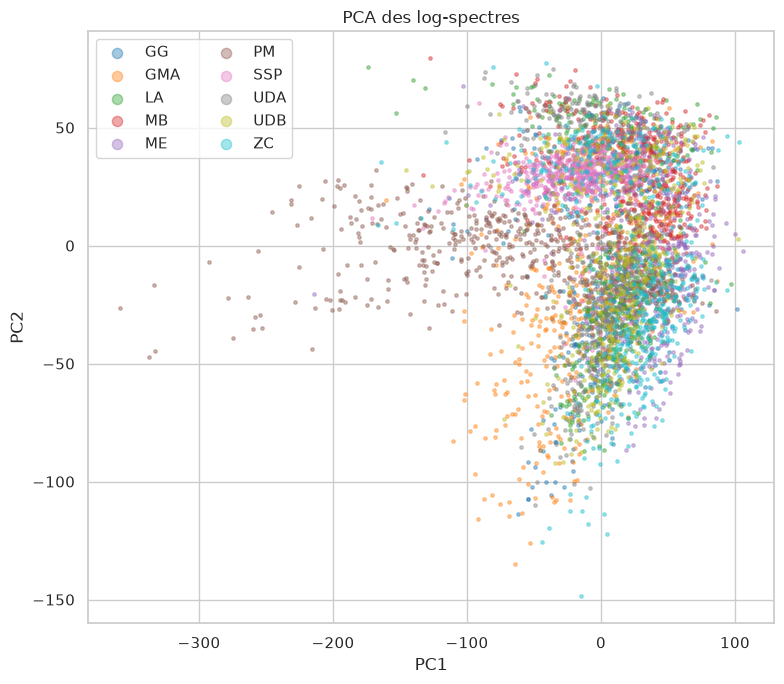

In [13]:
# Projection PCA des log-spectres individuels
Z = PCA(n_components=2, random_state=0).fit(LS)
Zp = Z.transform(LS)
print("Variance expliquée :", Z.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(figsize=(8, 7))
for e in especes:
    m = y_sub == e
    ax.scatter(Zp[m, 0], Zp[m, 1], s=6, alpha=0.4, color=palette[e], label=lab[e])
ax.legend(markerscale=3, ncol=2); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("PCA des log-spectres")
plt.tight_layout(); plt.show()

Accuracy kNN sur log-spectres (CV 5 plis, sous-échantillon) : 0.554


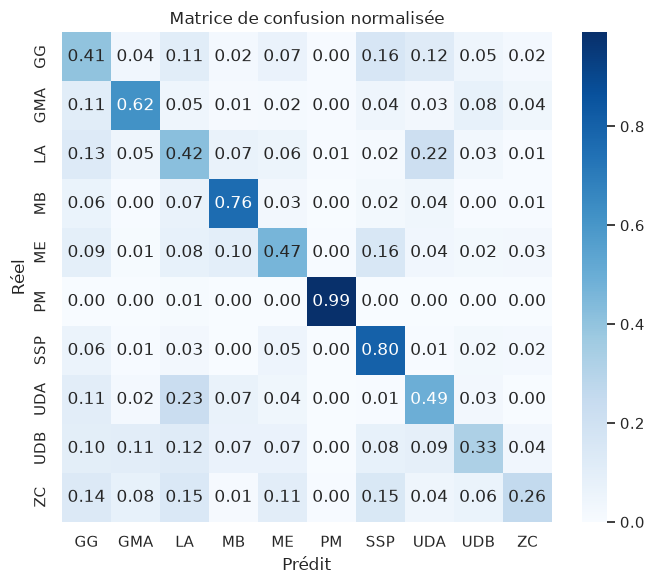

In [14]:
# Séparabilité rapide : kNN (k=5) en validation croisée sur les log-spectres
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, accuracy_score

pred = cross_val_predict(KNeighborsClassifier(5), LS, y_sub, cv=5)
print(f"Accuracy kNN sur log-spectres (CV 5 plis, sous-échantillon) : {accuracy_score(y_sub, pred):.3f}")
cm = confusion_matrix(y_sub, pred, labels=especes, normalize='true')
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=[lab[e] for e in especes], yticklabels=[lab[e] for e in especes])
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion normalisée"); plt.tight_layout(); plt.show()

## 2.5 Bruit de fond et choix de la bande de fréquences
Question : à partir de quelle fréquence le clic domine-t-il le bruit ? Cela justifie la fréquence de coupure du filtre passe-haut (section 3.1).
Le clic et le bruit sont comparés dans la même unité (amplitude divisée par le pic du clic).

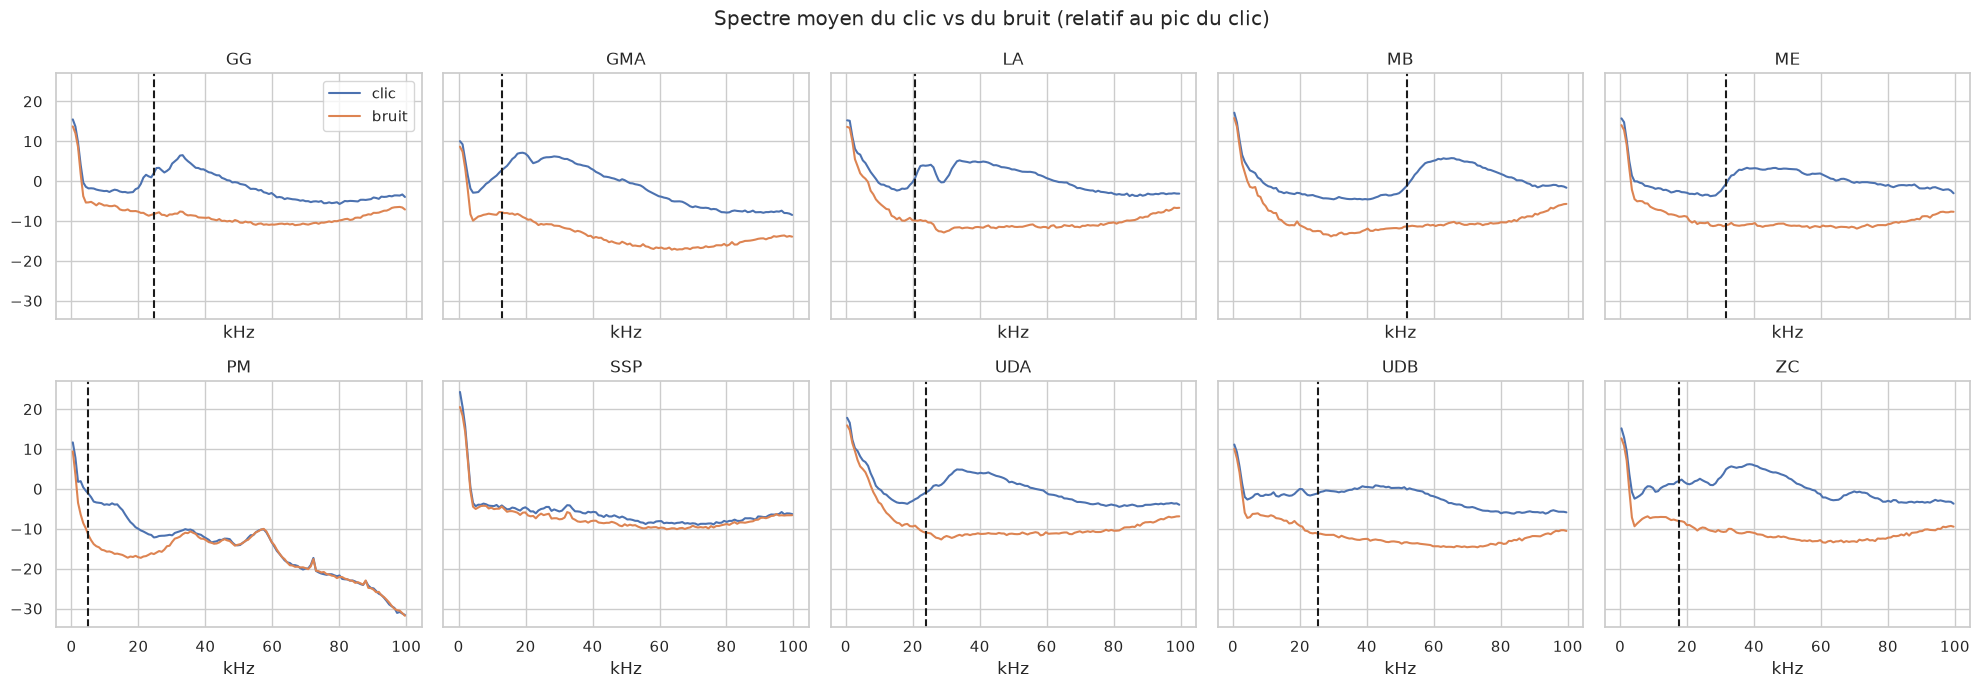

,f(clic - bruit >= 10 dB) kHz,marge max (dB),f de la marge max (kHz)
GG,24.6,14.2,33.2
GMA,12.9,17.5,32.4
LA,20.7,16.8,34.8
MB,52.0,16.8,62.9
ME,31.6,14.4,41.0
PM,5.1,12.4,12.9
SSP,NaN,3.8,0.4
UDA,23.8,16.6,33.2
UDB,25.4,13.9,50.4
ZC,17.6,17.1,41.0


NaN = le clic ne dépasse jamais le bruit de 10 dB dans le spectre moyen (marge max < 10 dB). La colonne 'marge max' indique de combien on en est loin.


,bruit <5 kHz,bruit >60 kHz
classe,,
GG,0.6946,0.1033
GMA,0.6767,0.0546
LA,0.7656,0.0686
MB,0.8101,0.0783
ME,0.7696,0.0785
PM,0.6399,0.0386
SSP,0.9009,0.0322
UDA,0.8099,0.0404
UDB,0.6602,0.0910


In [24]:
def far_segment(X, pos, n=512):
    start = np.where(pos > X.shape[1] // 2, 0, X.shape[1] - n)   # extrémité la plus éloignée du clic
    return np.take_along_axis(X, start[:, None] + np.arange(n)[None, :], axis=1)

def spec_db(seg):
    seg = seg - seg.mean(1, keepdims=True)
    S = np.abs(np.fft.rfft(seg * np.hanning(seg.shape[1]), n=1024, axis=1))[:, :512]
    return 20 * np.log10(S.reshape(len(seg), NB, -1).mean(2) + 1e-9)

N_seg = far_segment(X_sub, pos_sub)
peak_c = np.abs(C_sub).max(1, keepdims=True) + 1e-12
SC = spec_db(C_sub / peak_c)      # spectre du clic
SN = spec_db(N_seg / peak_c)      # spectre du bruit, même normalisation

SEUIL = 10   # dB
rows = {}
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True, sharey=True)
for ax, e in zip(axes.ravel(), especes):
    m = y_sub == e
    sc, sn = SC[m].mean(0), SN[m].mean(0)
    marge = sc - sn
    ok = np.where(marge >= SEUIL)[0]
    rows[lab[e]] = {'f(clic - bruit >= 10 dB) kHz': fbin[ok[0]] if len(ok) else np.nan,
                    'marge max (dB)': marge.max(),
                    'f de la marge max (kHz)': fbin[marge.argmax()]}
    ax.plot(fbin, sc, label='clic'); ax.plot(fbin, sn, label='bruit')
    if len(ok): ax.axvline(fbin[ok[0]], color='k', ls='--')
    ax.set_title(lab[e]); ax.set_xlabel("kHz")
axes[0, 0].legend(); plt.suptitle("Spectre moyen du clic vs du bruit (relatif au pic du clic)")
plt.tight_layout(); plt.show()

tab_fc = pd.DataFrame(rows).T.round(1)
display(tab_fc)
print("NaN = le clic ne dépasse jamais le bruit de 10 dB dans le spectre moyen (marge max < 10 dB). "
      "La colonne 'marge max' indique de combien on en est loin.")

# Répartition de l'énergie du bruit par bande
Pn = 10 ** (SN / 10)
frac = lambda mask: Pn[:, mask].sum(1) / Pn.sum(1)
tab = pd.DataFrame({'classe': [lab[e] for e in y_sub], 'bruit <5 kHz': frac(fbin < 5), 'bruit >60 kHz': frac(fbin > 60)})
display(tab.groupby('classe').median().round(4))

**Lecture.** Une valeur `NaN` signifie que, pour cette classe, le spectre moyen du clic ne dépasse jamais celui du bruit de 10 dB : le clic est trop peu énergétique par rapport au bruit, ou son énergie se situe hors de la bande observée (0-100 kHz). La colonne « marge max » quantifie l'écart, et la fréquence correspondante indique où se trouve l'énergie utile. Ce seuil de 10 dB est un choix de lecture, pas une propriété des données.

## 2.6 Durée du clic et taille de la fenêtre
Question : quelle largeur de fenêtre autour du pic contient l'essentiel de l'énergie du clic ? Cela fixe la taille de la fenêtre recentrée (section 3.2).

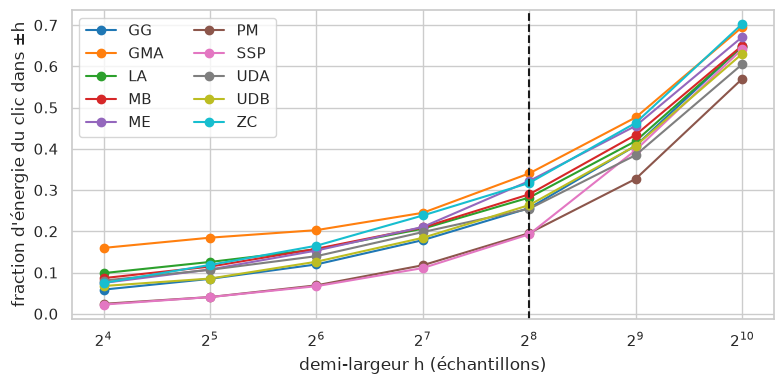

Fraction médiane d'énergie dans ±256 échantillons : 0.265


In [18]:
H = 2048
Cw = extract(X_sub, pos_sub, half=H)
off = pos_sub - np.clip(pos_sub, H, L - H)                      # position du pic dans la fenêtre
dist = np.abs(np.arange(-H, H)[None, :] - off[:, None])
e = np.maximum(Cw**2 - noise_rms[:, None]**2, 0)               # énergie en excès par rapport au bruit
tot = e.sum(1) + 1e-12
hs = [16, 32, 64, 128, 256, 512, 1024]
cum = np.stack([(e * (dist <= h)).sum(1) / tot for h in hs], 1)

fig, ax = plt.subplots(figsize=(8, 4))
for e_ in especes:
    ax.plot(hs, np.median(cum[y_sub == e_], 0), marker='o', color=palette[e_], label=lab[e_])
ax.set_xscale('log', base=2); ax.axvline(256, color='k', ls='--')
ax.set_xlabel("demi-largeur h (échantillons)"); ax.set_ylabel("fraction d'énergie du clic dans ±h")
ax.legend(ncol=2); plt.tight_layout(); plt.show()
print("Fraction médiane d'énergie dans ±256 échantillons :", np.median(cum[:, hs.index(256)]).round(3))

## 2.7 Amplitude et normalisation
Question : l'amplitude brute varie-t-elle beaucoup, et contient-elle de l'information sur l'espèce ? Si oui, c'est un raccourci lié au gain d'enregistrement, ce qui justifie la normalisation par le pic (section 3.2).

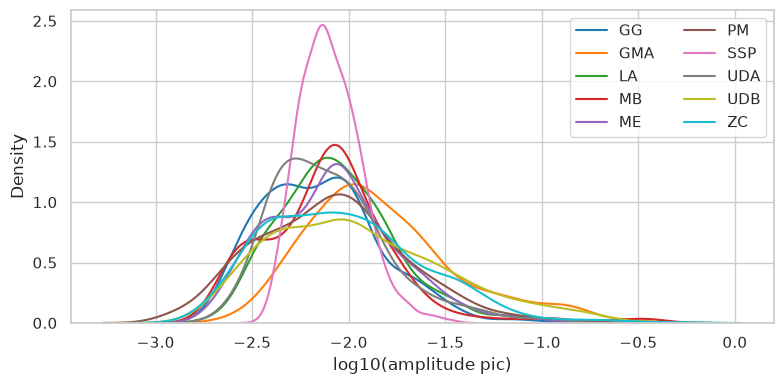

Accuracy avec uniquement (pic, rms) : 0.237 (hasard = 0.10)


In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

fig, ax = plt.subplots(figsize=(8, 4))
for e_ in especes:
    sns.kdeplot(np.log10(peak[y_sub == e_] + 1e-12), ax=ax, color=palette[e_], label=lab[e_])
ax.set_xlabel("log10(amplitude pic)"); ax.legend(ncol=2); plt.tight_layout(); plt.show()

A = np.log10(np.c_[peak, rms] + 1e-12)
pred = cross_val_predict(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), A, y_sub, cv=5)
print(f"Accuracy avec uniquement (pic, rms) : {accuracy_score(y_sub, pred):.3f} (hasard = 0.10)")

## 2.8 Qualité des données : bruit contaminé, multi-clics, doublons
Ces vérifications valident les analyses précédentes. Le tableau ci-dessous donne, **pour chaque classe, la proportion de clics du sous-échantillon** qui présentent le défaut indiqué :
- **segment de bruit contaminé** : l'enveloppe du segment de bruit (extrémité de la fenêtre, loin du clic) dépasse 50 % du pic du clic principal, donc ce segment contient probablement un autre clic ;
- **second pic** : en dehors de ±256 échantillons autour du clic principal, l'enveloppe dépasse 50 % du pic principal (fenêtre multi-clics, qui perturbe le recentrage) ;
- **SNR < 10 dB** : le clic est à moins de 10 dB au-dessus du bruit.

Les doublons exacts gonfleraient la validation.

In [25]:
start = np.where(pos_sub > L // 2, 0, L - 512)
env_far = np.take_along_axis(env_sub, start[:, None] + np.arange(512)[None, :], axis=1).max(1)
ratio_far = env_far / peak_env
mask = np.abs(ar[None, :] - pos_sub[:, None]) > HALF
ratio_second = np.where(mask, env_sub, 0).max(1) / peak_env

q = pd.DataFrame({'classe': [lab[e] for e in y_sub],
                  'segment de bruit contaminé (%)': ratio_far > 0.5,
                  'second pic hors ±256 (%)': ratio_second > 0.5,
                  'SNR < 10 dB (%)': snr_db < 10})
display((q.groupby('classe').mean() * 100).round(1))

h = pd.Series([hash(X_train[i, 2000:2512].tobytes()) for i in range(len(X_train))])
dup = h.duplicated(keep=False)
print("Doublons exacts :", int(dup.sum()), "/", len(h))
if dup.any(): print(pd.Series(y_labels[dup.values]).map(lab).value_counts().to_string())

,segment de bruit contaminé (%),second pic hors ±256 (%),SNR < 10 dB (%)
classe,,,
GG,54.6,75.4,21.2
GMA,37.8,56.4,19.6
LA,46.6,66.6,13.4
MB,49.8,69.6,16.8
ME,52.8,66.8,24.8
PM,89.2,98.2,75.0
SSP,84.4,99.8,48.0
UDA,54.6,73.0,11.6
UDB,53.8,68.4,19.6


Doublons exacts : 0 / 113120


## 2.9 Biais d'enregistrement : le bruit seul identifie-t-il l'espèce ?
Les classes viennent de déploiements différents (et Pm d'un autre instrument). On compare ici trois sources d'information : le clic seul, le bruit seul (forme spectrale), et le bruit avec son niveau (relatif au pic du clic). Un score du bruit seul bien supérieur à 10 % révèle un raccourci exploitable.

clic seul (forme spectrale)     0.563
bruit seul (forme spectrale)    0.436
bruit seul (forme + niveau)     0.446
clic + bruit                    0.574 
(hasard = 0.10)


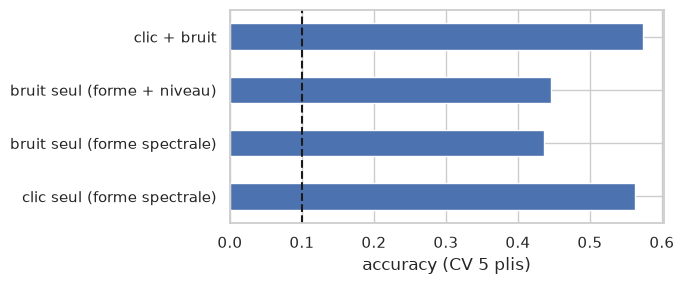

In [22]:
def cv_acc(F):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    return accuracy_score(y_sub, cross_val_predict(clf, F, y_sub, cv=5))

SC_shape = SC - SC.mean(1, keepdims=True)
SN_shape = SN - SN.mean(1, keepdims=True)

res = pd.Series({
    'clic seul (forme spectrale)': cv_acc(SC_shape),
    'bruit seul (forme spectrale)': cv_acc(SN_shape),
    'bruit seul (forme + niveau)': cv_acc(SN),
    'clic + bruit': cv_acc(np.c_[SC_shape, SN_shape]),
})
print(res.round(3).to_string(), "\n(hasard = 0.10)")
res.plot.barh(figsize=(7, 3)); plt.axvline(0.1, color='k', ls='--'); plt.xlabel("accuracy (CV 5 plis)"); plt.tight_layout(); plt.show()

NMI clusters de bruit vs espèces : 0.34


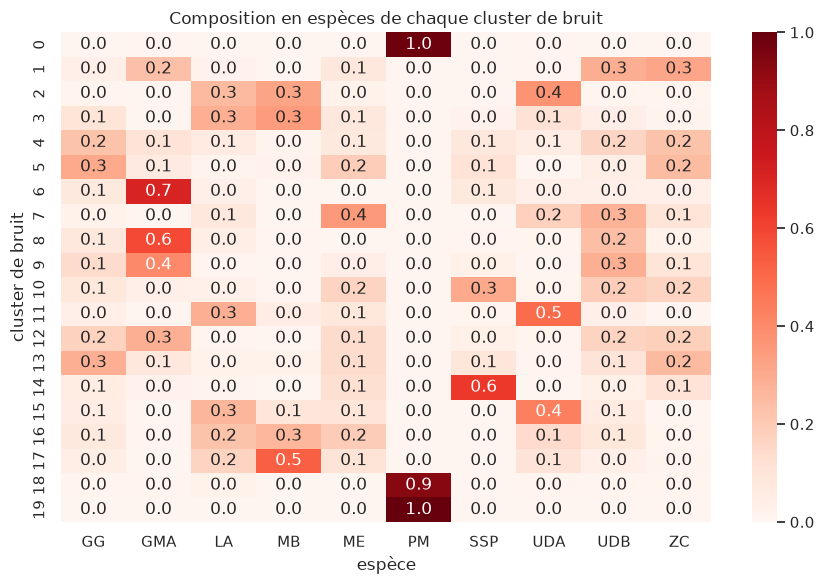

In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score

Z = StandardScaler().fit_transform(SN_shape)
cl = KMeans(n_clusters=20, n_init=10, random_state=0).fit_predict(Z)
print("NMI clusters de bruit vs espèces :", round(normalized_mutual_info_score(y_sub, cl), 3))

ct = pd.crosstab(cl, [lab[e] for e in y_sub], normalize='index')[[lab[e] for e in especes]]
plt.figure(figsize=(9, 6)); sns.heatmap(ct, cmap='Reds', annot=True, fmt='.1f')
plt.xlabel("espèce"); plt.ylabel("cluster de bruit"); plt.title("Composition en espèces de chaque cluster de bruit")
plt.tight_layout(); plt.show()

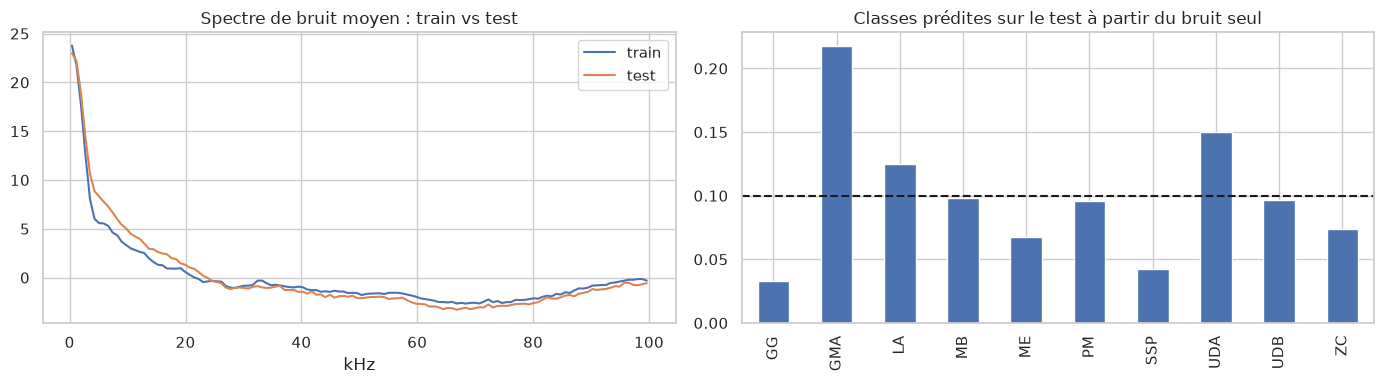

Confiance moyenne du modèle bruit-seul sur le test : 0.533
Distance à la distribution uniforme (0 = parfaitement équilibré) : 0.193


In [26]:
Nt = far_segment(Xt_sub, pos_te)
Ct = extract(Xt_sub, pos_te)
SN_te = spec_db(Nt / (np.abs(Ct).max(1, keepdims=True) + 1e-12))
SN_te_shape = SN_te - SN_te.mean(1, keepdims=True)

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(SN_shape, y_sub)
proba = clf.predict_proba(SN_te_shape)
pred_te = clf.classes_[proba.argmax(1)]

# Le test est équilibré (2096 clics par classe) : une distribution prédite très inégale
# montre que le modèle de bruit "reconnaît" des environnements du test.
dist_pred = pd.Series(pred_te).map(lab).value_counts(normalize=True).reindex([lab[e] for e in especes]).fillna(0)
tvd = 0.5 * np.abs(dist_pred.values - 0.1).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(fbin, SN_shape.mean(0), label='train'); axes[0].plot(fbin, SN_te_shape.mean(0), label='test')
axes[0].set_xlabel("kHz"); axes[0].legend(); axes[0].set_title("Spectre de bruit moyen : train vs test")
dist_pred.plot.bar(ax=axes[1]); axes[1].axhline(0.1, color='k', ls='--')
axes[1].set_title("Classes prédites sur le test à partir du bruit seul")
plt.tight_layout(); plt.show()
print(f"Confiance moyenne du modèle bruit-seul sur le test : {proba.max(1).mean():.3f}")
print(f"Distance à la distribution uniforme (0 = parfaitement équilibré) : {tvd:.3f}")

**Lecture.** Les étiquettes du test ne sont pas disponibles, donc on ne peut pas mesurer d'accuracy. Mais le test est équilibré (10 % par classe), donc si un modèle qui ne voit que le bruit prédit des proportions très éloignées de 10 %, ou avec une confiance élevée, c'est que le bruit du test ressemble à celui de classes précises du train. Cela indique que le raccourci « environnement » est aussi présent dans le test et donc exploitable. À l'inverse, des prédictions proches de l'uniforme avec une faible confiance suggéreraient que le test est moins concerné.

## Synthèse : de l'analyse au prétraitement
| Constat (analyse) | Choix de prétraitement |
|---|---|
| Le bruit domine à basse fréquence ; le clic émerge au-dessus de la fréquence trouvée en 2.5 | Filtre passe-haut à phase nulle (3.1) |
| La plupart de l'énergie du clic tient dans ±256 échantillons (2.6) | Fenêtre de 512 points autour du clic (3.2) |
| Position du clic variable en train, centrée en test (2.2) | Recentrage sur le maximum de l'enveloppe (3.2) |
| L'amplitude varie sur plusieurs ordres de grandeur et prédit en partie l'espèce (2.7) | Normalisation par le pic (3.2) |
| Le bruit seul prédit l'espèce bien au-dessus du hasard (2.9) ; Pm se distingue par sa coupure spectrale | Le prétraitement ne suffit pas : correction du biais par échange de bruit (parties 5 et 6) |

## WARNING !!!!!!

Minor Suggestions for Refinement:

**Section 2.5 (Bruit de fond)** - Handling NaN: In the calculation of the first frequency where SNR >= 10dB, SSP returns NaN. This means the click never exceeds the noise by 10dB in the average spectrum. It might be worth adding a brief comment explaining why SSP is NaN (likely due to very low SNR or a different spectral profile) so the reader isn't confused.

**Section 2.8 (Qualité des données)** - Clarity on Ratios: The table in 2.8 is useful, but the column names are slightly ambiguous. For example, 'bruit contaminé (>0.5)'. Does this mean 54.6% of 'GG' samples have a noise segment envelope peak that is > 50% of the main click peak? A tiny explanatory sentence before the table would clarify this.

**Section 2.9 (Biais)** - Test Set Evaluation: In the final cell of 2.9, you evaluate the noise-only model on the test set. It would be insightful to print the actual accuracy of that prediction (accuracy_score(y_test_sub, pred_te)) alongside the mean confidence. However, since you don't seem to have loaded the true labels for the test set in this notebook, just showing the predicted class distribution (as you did in the bar chart) is a good alternative to show how the model behaves on unseen data.